In [74]:
import pandas as pd 
import geopandas as gpd
import matplotlib.pyplot as plt

# Analyse descriptive

## Comparaison des PIB par habitant des différentes régions de France

In [75]:
# Récupérer les années sur la ligne d'indice 3
annees = pib_brut.iloc[3, 2:].tolist()

# Récupérer les données à partir de la ligne d'indice 4 et supprimer les 5 dernières lignes(vides)
pib = pib_brut.iloc[4: -6: , [0] + list(range(2, pib_brut.shape[1]))].copy()

# Renommer les colonnes
pib.columns = ["Région"] + annees[:len(pib.columns) - 1]
pib = pib.dropna(subset=["Région"])

display(pib.head())
display(pib.tail())

,Région,1991.0,1992.0,1993.0,1994.0,1995.0,1996.0,1997.0,1998.0,1999.0,...,2015.0,2016.0,2017.0,2018.0,2019.0,2020.0,2021.0,2022.0,2023.0,2024.0
4,Île-de-France,29686.225,30547.412,30977.593,31826.682,32218.099,33077.916,34266.294,35401.260,37478.029,...,54116.636,54871.051,55995.849,57557.217,59754.742,55056.603,59374.473,63183.529,66752.891,69513.539
5,Centre-Val de Loire,16964.458,17460.353,17509.278,17995.778,18667.464,18971.392,19303.832,20147.774,20628.338,...,27835.070,27906.933,28562.750,29045.004,29717.614,28653.517,30513.269,31520.369,34750.329,35450.990
6,Bourgogne-Franche-Comté,16064.622,16469.780,16399.530,16918.502,17684.035,18088.539,18613.075,19468.814,19875.046,...,27116.903,27158.547,28024.636,28511.240,29167.151,28345.563,29943.038,31337.406,33260.052,34216.177
7,Normandie,16432.151,16985.444,17080.662,17681.875,18219.987,18470.369,18864.622,19524.381,20056.475,...,28395.813,28250.457,28506.829,28920.611,29561.660,28438.906,30342.939,31997.425,34504.584,35286.669
8,Hauts-de-France,14791.580,15284.773,15364.888,15831.979,16459.863,16886.435,17161.200,18056.593,18340.929,...,25853.580,25891.782,26654.272,27038.836,27657.297,26706.012,28420.889,29901.698,31958.593,32890.967


,Région,1991.0,1992.0,1993.0,1994.0,1995.0,1996.0,1997.0,1998.0,1999.0,...,2015.0,2016.0,2017.0,2018.0,2019.0,2020.0,2021.0,2022.0,2023.0,2024.0
22,Guadeloupe (y compris Saint-Martin),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,23881.459,24525.477,22835.933,23486.922,24363.904,23478.238,25101.175,26386.770,27487.479,29099.216
23,Mayotte*,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,8229.573,8409.083,8872.948,8648.197,9102.062,9364.152,10115.902,10958.635,11977.241,NaN
24,Départements d'Outre-mer,10335.411,10529.183,10880.164,11062.914,11581.271,11893.742,12345.518,12804.227,13342.138,...,19930.602,20226.988,20253.385,20509.425,20966.000,20477.906,21832.444,23072.011,24035.418,25006.806
25,France,18513.056,19081.914,19228.949,19803.189,20421.017,20907.098,21548.791,22414.821,23110.613,...,33182.372,33514.918,34276.541,35069.918,36073.894,34266.014,36903.321,38901.985,41325.005,42578.750
26,Territoire économique de la France,18522.916,19092.127,19239.245,19813.721,20431.873,20918.167,21560.209,22426.700,23122.866,...,33196.695,33529.238,34291.022,35084.227,36088.153,34280.193,36917.197,38916.638,41340.454,42594.159


In [76]:
# Sélectionner les données de 2023
pib_2023 = pib[["Région", 2023.0]].copy()
pib_2023 = pib_2023.rename(columns={2023.0: "PIB_par_habitant"})

display(pib_2023)

,Région,PIB_par_habitant
4,Île-de-France,66752.891
5,Centre-Val de Loire,34750.329
6,Bourgogne-Franche-Comté,33260.052
7,Normandie,34504.584
8,Hauts-de-France,31958.593
9,Grand Est,34587.842
10,Pays de la Loire,36710.348
11,Bretagne,35429.082
12,Nouvelle-Aquitaine,35518.853
13,Occitanie,35126.693


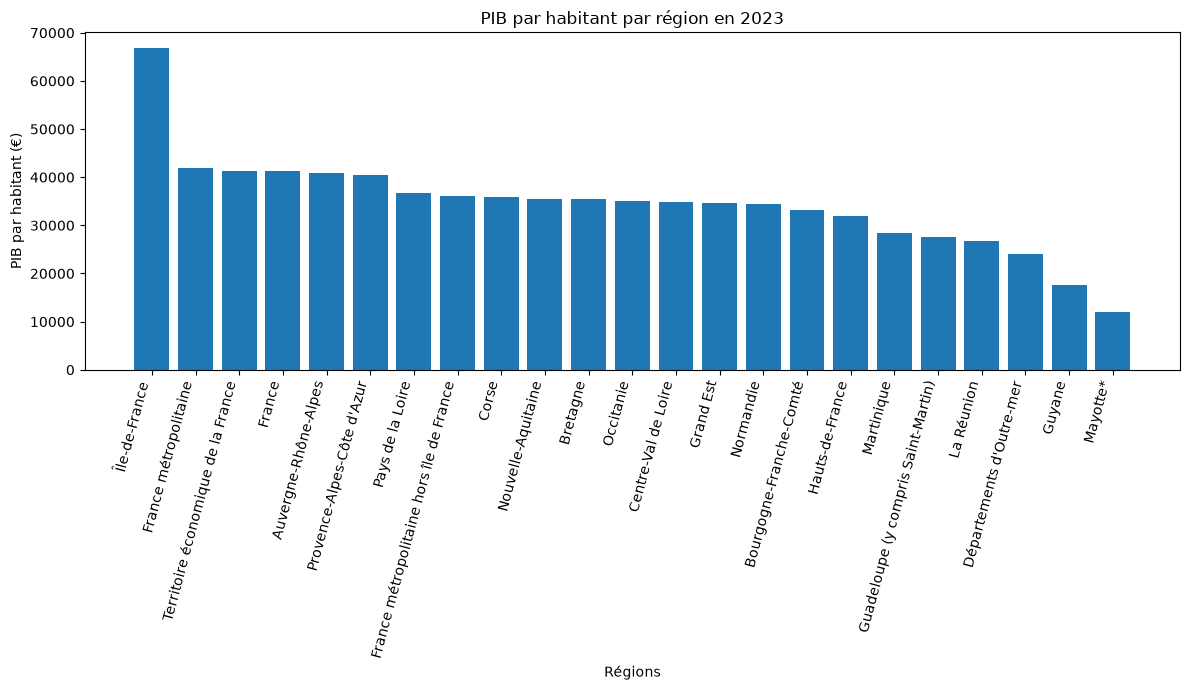

In [77]:
classement_2023 = pib_2023.sort_values( by="PIB_par_habitant", ascending=False )

plt.figure(figsize=(12, 7))

plt.bar( classement_2023["Région"], classement_2023["PIB_par_habitant"])

plt.title("PIB par habitant par région en 2023")
plt.xlabel("Régions")
plt.ylabel("PIB par habitant (€)")
plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.show()

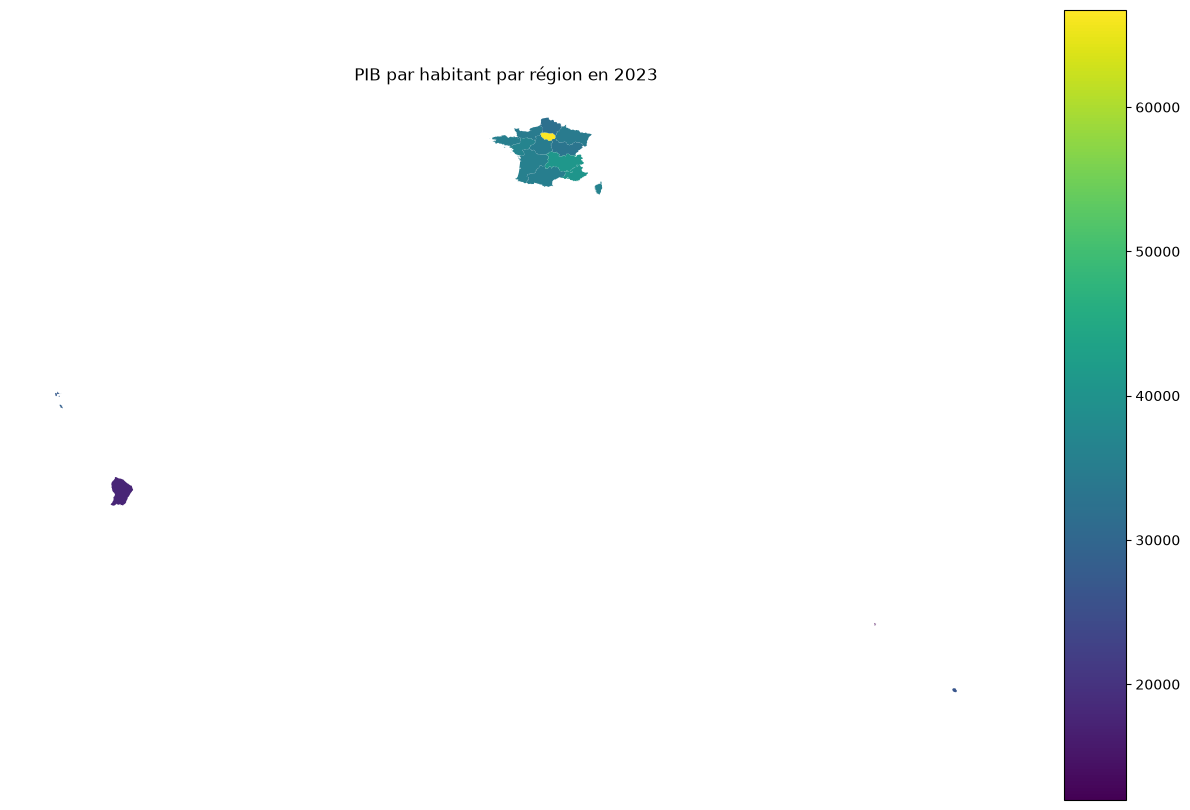

In [78]:
# Charger la carte des régions françaises
url = "https://france-geojson.gregoiredavid.fr/repo/regions.geojson"
regions = gpd.read_file(url)

# Renommer la colonne des régions
regions = regions.rename(columns={"nom": "Région"})

# Corriger les noms des régions
pib_2023["Région"] = pib_2023["Région"].str.strip()

pib_2023["Région"] = pib_2023["Région"].replace({
    "Guadeloupe (y compris Saint-Martin)": "Guadeloupe",
    "Mayotte*": "Mayotte"
        })

# Retirer les lignes qui ne correspondent pas à des régions
pib_carte = pib_2023[
    ~pib_2023["Région"].isin([
        "France métropolitaine",
        "France métropolitaine hors île de France",
        "Départements d'Outre-mer",
        "France",
        "Territoire économique de la France"
    ])
].copy()

# Associer les données du PIB à la carte
carte = regions.merge(pib_carte, on="Région", how="left")

# Afficher la carte
fig, ax = plt.subplots(figsize=(16, 16))

carte.plot( column="PIB_par_habitant", legend=True, ax=ax )

ax.set_title("PIB par habitant par région en 2023")
ax.axis("off")
plt.show()